# 04. Результати: таблиці, графіки, аналіз

**Структура:**
0. Зведена таблиця експериментів
1. E1 — AE проти VAE
2. Збіжність навчання
3. E2 — розмір латенту; 2D-латентний простір
4. E3 — β-VAE
5. E4 — архітектура
6. E5 — вибіркова ефективність
7. E6 — Conditional VAE
8. Стабільність між сідами
9. Аналіз помилок
10. Інтерполяції
11. Висновки

In [ ]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir() and (p / "configs").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

%matplotlib inline
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from src.experiment import collect_results, load_history, load_run_model
from src.utils import load_config, run_name, load_json, get_device, RESULTS_DIR, TABLES_DIR
from src.data import get_data
from src.train import load_evaluator
from src.metrics import classifier_outputs, collect_latents, fit_gaussian, generate
from src.losses import reconstruction_loss
from src.viz import (setup_style, show_grid, save_fig, plot_curves_band, plot_metric_vs_param,
                     latent_scatter, latent_manifold, interpolate, ordered_colors, COLORS, BLUES, MUTED)

setup_style()
pd.set_option("display.max_columns", 30)

# Має збігатися з 03_experiments.ipynb
QUICK = False
OVERRIDES = {"train.steps": 300, "train.eval_every": 100, "eval.n_generated": 2000} if QUICK else None
SEEDS = [0, 1, 2]

device = get_device()
clf = load_evaluator(device)
base_cfg = load_config(overrides=OVERRIDES or {})
data = get_data(base_cfg, device)
x_test = torch.cat([b[0] for b in data["test"]])
y_test = torch.cat([b[1] for b in data["test"]])

df_all = collect_results(OVERRIDES)
df = df_all[df_all["status"] == "ok"].copy()
ref_path = RESULTS_DIR / "reference_metrics.json"
REF = load_json(ref_path) if ref_path.exists() else {}
print(f"Запусків: {df_all['run'].nunique()} (успішних {df['run'].nunique()}); референс: {REF}")

Запусків: 63 (успішних 63); референс: {'evaluator_test_acc': 0.9927, 'fid_train_vs_test': 4.24161916306457, 'real_ambiguous_share_test': 0.0205, 'real_mean_conf_test': 0.9926937222480774}


In [3]:
# ---------- допоміжні функції ----------
LIST_COLS = ["kl_per_dim", "class_hist", "cond_acc_per_class"]
df.drop(columns=[c for c in LIST_COLS if c in df]).to_csv(TABLES_DIR / "all_runs.csv", index=False)

NAMES = {"test_recon": "recon (BCE)", "test_kl": "KL", "test_nelbo": "−ELBO", "recon_mse": "MSE",
         "active_units": "активні виміри", "fid_prior": "FID (N(0,I))", "fid_fitted": "FID (fitted)",
         "class_entropy": "ентропія класів", "ambiguous_share": "неоднозначні", "mean_conf": "впевненість",
         "cond_acc": "cond. acc", "best_step": "найкращий крок", "train_time_s": "час, с", "gap": "val−train"}


def rn(ov=None, seed=0):
    """Назва запуску для base-конфігу зі змінами ov (ключі з крапкою)."""
    return run_name(load_config(overrides={**(ov or {}), "seed": seed, **(OVERRIDES or {})}))


def runs_for(ov=None):
    return [r for r in (rn(ov, s) for s in SEEDS) if r in set(df["run"])]


def histories(ov=None):
    return [load_history(r) for r in runs_for(ov)]


def exp_df(name):
    return df[df["experiment"] == name].copy()


def agg_table(d, by, metrics):
    """mean ± std по сідах."""
    by = [by] if isinstance(by, str) else by
    g = d.groupby(by)
    out = pd.DataFrame({"n": g.size()})
    for m in metrics:
        if m not in d or d[m].isna().all():
            continue
        mean, std = g[m].mean(), g[m].std()
        dec = 3 if mean.abs().max() < 10 else 1
        out[NAMES.get(m, m)] = ["—" if pd.isna(a) else f"{a:.{dec}f}" + (f" ± {s:.{dec}f}" if pd.notna(s) else "")
                                for a, s in zip(mean, std)]
    return out.reset_index()


def save_table(t, name):
    t.to_csv(TABLES_DIR / f"{name}.csv", index=False)
    (TABLES_DIR / f"{name}.md").write_text(t.to_markdown(index=False), encoding="utf-8")
    return t


MAIN = ["test_recon", "test_kl", "test_nelbo", "active_units", "fid_prior", "fid_fitted",
        "class_entropy", "ambiguous_share", "cond_acc"]

## 0. Зведена таблиця експериментів

Одна строка = одна конфігурація (усереднено по сідах). Метрики на **тесті**; менше = краще для recon, −ELBO, FID, частки неоднозначних.

In [4]:
PARAMS = ["experiment", "model_type", "arch", "latent_dim", "beta", "train_fraction"]
exp_table = save_table(agg_table(df, PARAMS, MAIN + ["best_step", "train_time_s"]), "experiments_table")
exp_table

,experiment,model_type,arch,latent_dim,beta,train_fraction,n,recon (BCE),KL,−ELBO,активні виміри,"FID (N(0,I))",FID (fitted),ентропія класів,неоднозначні,cond. acc,найкращий крок,"час, с"
0,e1_ae_vs_vae,ae,conv,16,1.0,1.00,3,63.1 ± 0.1,0.0 ± 0.0,63.1 ± 0.1,—,1943.4 ± 229.8,440.1 ± 12.0,0.805 ± 0.049,0.902 ± 0.054,—,12000.0 ± 0.0,62.9 ± 1.2
1,e1_ae_vs_vae,vae,conv,16,1.0,1.00,3,74.9 ± 0.8,21.7 ± 0.6,96.6 ± 0.2,14.0 ± 1.0,277.1 ± 16.0,257.7 ± 16.8,0.994 ± 0.001,0.315 ± 0.011,—,11666.7 ± 288.7,78.6 ± 2.1
2,e2_latent_dim,vae,conv,2,1.0,1.00,3,137.0 ± 1.1,6.6 ± 0.1,143.6 ± 1.0,2.0 ± 0.0,641.9 ± 61.7,661.9 ± 54.4,0.972 ± 0.002,0.246 ± 0.022,—,12000.0 ± 0.0,79.4 ± 0.4
3,e2_latent_dim,vae,conv,4,1.0,1.00,3,110.5 ± 0.9,10.9 ± 0.2,121.4 ± 0.6,4.0 ± 0.0,281.2 ± 16.2,280.5 ± 14.7,0.995 ± 0.004,0.180 ± 0.007,—,11666.7 ± 577.4,79.9 ± 0.7
4,e2_latent_dim,vae,conv,8,1.0,1.00,3,85.5 ± 0.3,16.9 ± 0.1,102.4 ± 0.4,8.0 ± 0.0,238.2 ± 37.0,219.7 ± 19.1,0.995 ± 0.002,0.263 ± 0.016,—,11500.0 ± 866.0,80.2 ± 0.4
5,e2_latent_dim,vae,conv,16,1.0,1.00,3,74.9 ± 0.8,21.7 ± 0.6,96.6 ± 0.2,14.0 ± 1.0,277.1 ± 16.0,257.7 ± 16.8,0.994 ± 0.001,0.315 ± 0.011,—,11666.7 ± 288.7,78.6 ± 2.1
6,e2_latent_dim,vae,conv,32,1.0,1.00,3,74.7 ± 0.4,22.2 ± 0.4,97.0 ± 0.1,16.3 ± 3.2,284.1 ± 2.8,256.3 ± 18.8,0.991 ± 0.002,0.320 ± 0.001,—,11666.7 ± 288.7,80.1 ± 0.3
7,e2_latent_dim,vae,conv,64,1.0,1.00,3,74.9 ± 0.7,22.3 ± 0.2,97.2 ± 0.5,17.7 ± 4.7,287.4 ± 31.5,263.8 ± 17.1,0.993 ± 0.002,0.318 ± 0.011,—,11833.3 ± 288.7,80.9 ± 0.2
8,e3_beta,vae,conv,16,0.1,1.00,3,63.8 ± 0.2,47.2 ± 0.3,111.1 ± 0.1,16.0 ± 0.0,547.7 ± 15.9,406.3 ± 3.0,0.957 ± 0.009,0.491 ± 0.005,—,12000.0 ± 0.0,80.7 ± 0.2
9,e3_beta,vae,conv,16,0.5,1.00,3,68.4 ± 0.2,29.8 ± 0.3,98.1 ± 0.2,16.0 ± 0.0,344.4 ± 19.1,307.2 ± 7.5,0.987 ± 0.005,0.373 ± 0.014,—,12000.0 ± 0.0,80.9 ± 0.4


## 1. E1 — AE проти VAE

Очікування: AE відновлює краще (немає KL-штрафу), але генерація з N(0, I) у нього непридатна, бо його латенти
не розподілені як N(0, I). Чесніше порівняння для AE — генерувати з Гаусіани, підігнаної до його латентів (`FID fitted`).

In [5]:
d1 = exp_df("e1_ae_vs_vae")
save_table(agg_table(d1, "model_type", ["test_recon", "recon_mse", "test_kl", "fid_prior", "fid_fitted",
                                       "ambiguous_share", "class_entropy"]), "e1_ae_vs_vae")

,model_type,n,recon (BCE),MSE,KL,"FID (N(0,I))",FID (fitted),неоднозначні,ентропія класів
0,ae,3,63.1 ± 0.1,0.006 ± 0.000,0.0 ± 0.0,1943.4 ± 229.8,440.1 ± 12.0,0.902 ± 0.054,0.805 ± 0.049
1,vae,3,74.9 ± 0.8,0.008 ± 0.000,21.7 ± 0.6,277.1 ± 16.0,257.7 ± 16.8,0.315 ± 0.011,0.994 ± 0.001


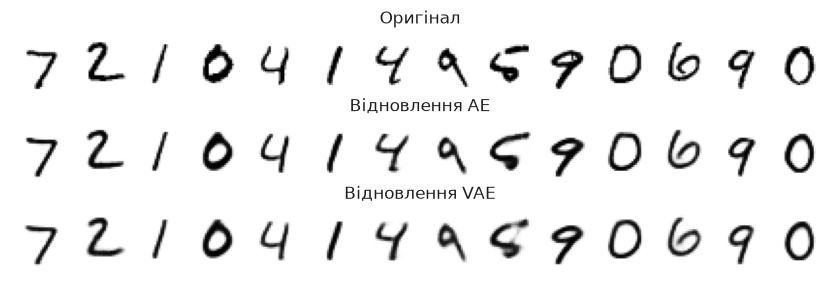

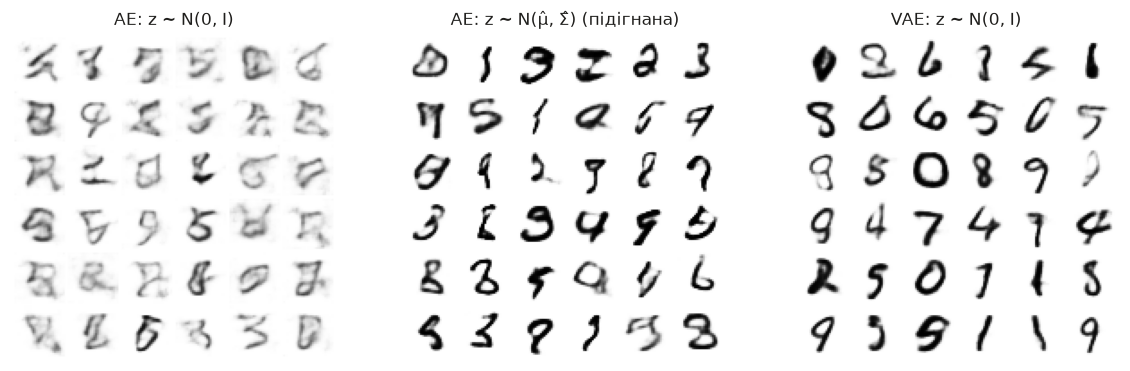

In [6]:
ae, _ = load_run_model(rn({"model.type": "ae"}), device)
vae, _ = load_run_model(rn(), device)
x = x_test[:14]
fig, axes = plt.subplots(3, 1, figsize=(8, 2.6))
show_grid(x, 1, axes[0], "Оригінал")
show_grid(ae.reconstruct(x), 1, axes[1], "Відновлення AE")
show_grid(vae.reconstruct(x), 1, axes[2], "Відновлення VAE")
fig.tight_layout()
save_fig(fig, "e1_reconstructions")
plt.show()

torch.manual_seed(0)
mean, cov = fit_gaussian(collect_latents(ae, data["train"])[0])
fig, axes = plt.subplots(1, 3, figsize=(13, 4.6))
show_grid(ae.sample(36), 6, axes[0], "AE: z ~ N(0, I)")
show_grid(generate(ae, 36, mean=mean, cov=cov), 6, axes[1], "AE: z ~ N(μ̂, Σ̂) (підігнана)")
show_grid(vae.sample(36), 6, axes[2], "VAE: z ~ N(0, I)")
save_fig(fig, "e1_samples")
plt.show()

## 2. Збіжність навчання

Криві на основній конфігурації (VAE, conv, d = 16, β = 1): середнє по 3 сідах ± std (смуга).
Дивимось: чи зійшлося навчання за 12k кроків, чи є перенавчання (val росте, train падає), як поводяться recon і KL окремо.

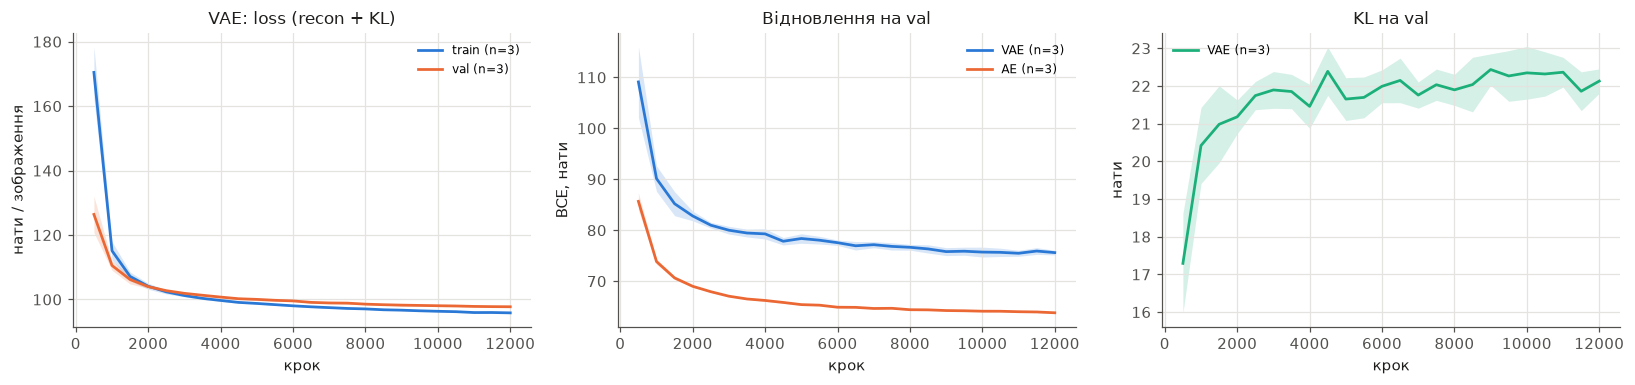

Наприкінці: train loss 95.84, val loss 97.74 (різниця 1.90); найкращий крок: [12000, 11500, 11500, 12000, 11500, 11500, 12000, 11500, 11500, 12000, 11500, 11500, 12000, 11500, 11500]


In [7]:
h_vae, h_ae = histories(), histories({"model.type": "ae"})
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
plot_curves_band({"train": h_vae}, "train_loss", axes[0], colors=[COLORS[0]])
plot_curves_band({"val": h_vae}, "val_loss", axes[0], colors=[COLORS[1]], title="VAE: loss (recon + KL)",
                 ylabel="нати / зображення")
plot_curves_band({"VAE": h_vae, "AE": h_ae}, "val_recon", axes[1], title="Відновлення на val",
                 ylabel="BCE, нати")
plot_curves_band({"VAE": h_vae}, "val_kl", axes[2], colors=[COLORS[2]], title="KL на val", ylabel="нати")
fig.tight_layout()
save_fig(fig, "convergence_main")
plt.show()

last = pd.DataFrame([h.iloc[-1] for h in h_vae])
print(f"Наприкінці: train loss {last.train_loss.mean():.2f}, val loss {last.val_loss.mean():.2f} "
      f"(різниця {(last.val_loss - last.train_loss).mean():.2f}); "
      f"найкращий крок: {df[df.run.isin(runs_for())].best_step.tolist()}")

## 3. E2 — розмір латентного простору

- Малий d → модель не може закодувати деталі → гірше відновлення.
- Великий d → частина вимірів «вимикається» (KL ≈ 0, **posterior collapse**): активних вимірів менше, ніж d.

In [8]:
d2 = exp_df("e2_latent_dim")
save_table(agg_table(d2, "latent_dim", ["test_recon", "test_kl", "test_nelbo", "active_units",
                                        "fid_prior", "ambiguous_share"]), "e2_latent_dim")

,latent_dim,n,recon (BCE),KL,−ELBO,активні виміри,"FID (N(0,I))",неоднозначні
0,2,3,137.0 ± 1.1,6.6 ± 0.1,143.6 ± 1.0,2.0 ± 0.0,641.9 ± 61.7,0.246 ± 0.022
1,4,3,110.5 ± 0.9,10.9 ± 0.2,121.4 ± 0.6,4.0 ± 0.0,281.2 ± 16.2,0.180 ± 0.007
2,8,3,85.5 ± 0.3,16.9 ± 0.1,102.4 ± 0.4,8.0 ± 0.0,238.2 ± 37.0,0.263 ± 0.016
3,16,3,74.9 ± 0.8,21.7 ± 0.6,96.6 ± 0.2,14.0 ± 1.0,277.1 ± 16.0,0.315 ± 0.011
4,32,3,74.7 ± 0.4,22.2 ± 0.4,97.0 ± 0.1,16.3 ± 3.2,284.1 ± 2.8,0.320 ± 0.001
5,64,3,74.9 ± 0.7,22.3 ± 0.2,97.2 ± 0.5,17.7 ± 4.7,287.4 ± 31.5,0.318 ± 0.011


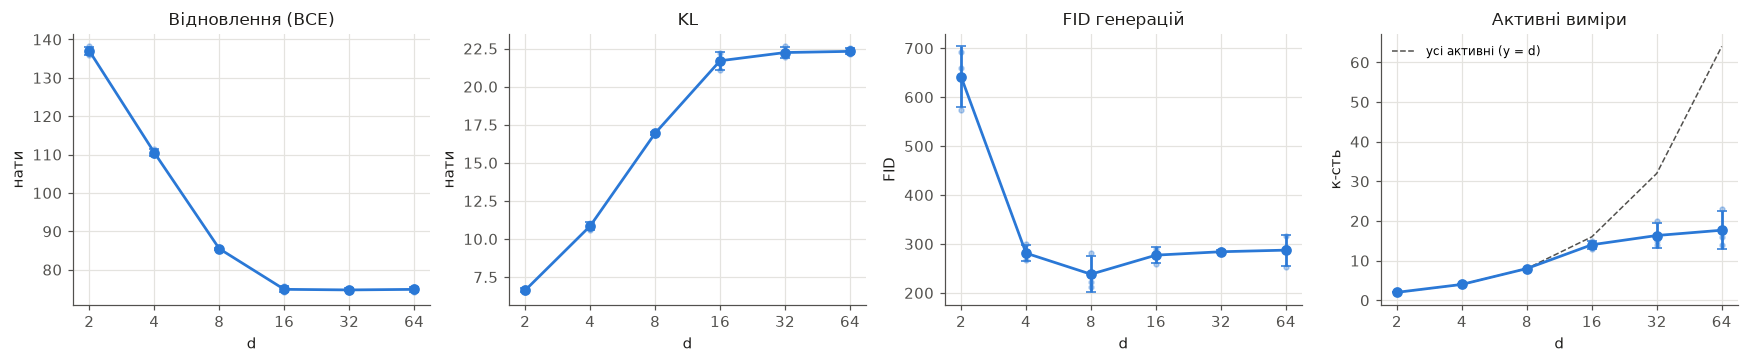

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
plot_metric_vs_param(d2, "latent_dim", "test_recon", axes[0], logx=True, xlabel="d", ylabel="нати",
                     title="Відновлення (BCE)")
plot_metric_vs_param(d2, "latent_dim", "test_kl", axes[1], logx=True, xlabel="d", ylabel="нати", title="KL")
plot_metric_vs_param(d2, "latent_dim", "fid_prior", axes[2], logx=True, xlabel="d", ylabel="FID",
                     title="FID генерацій")
plot_metric_vs_param(d2, "latent_dim", "active_units", axes[3], logx=True, xlabel="d", ylabel="к-сть",
                     title="Активні виміри")
dims = sorted(d2.latent_dim.unique())
axes[3].plot(dims, dims, ls="--", color=MUTED, lw=1, label="усі активні (y = d)")
axes[3].legend(fontsize=8)
fig.tight_layout()
save_fig(fig, "e2_latent_dim_metrics")
plt.show()

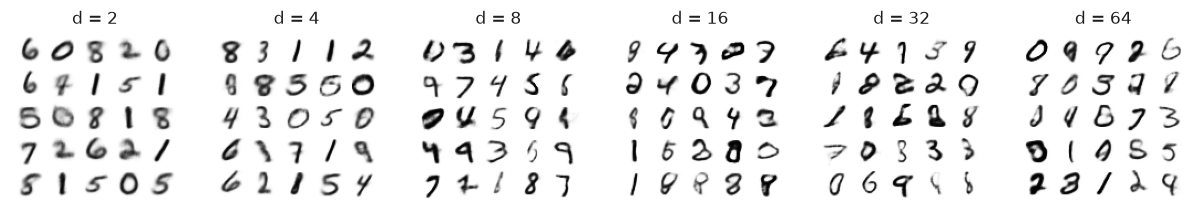

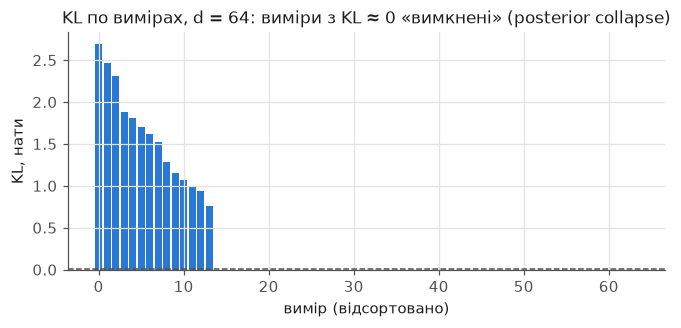

In [10]:
fig, axes = plt.subplots(1, len(dims), figsize=(2.3 * len(dims), 2.6))
torch.manual_seed(0)
for ax, dd in zip(axes, dims):
    m, _ = load_run_model(rn({"model.latent_dim": int(dd)}), device)
    show_grid(m.sample(25), 5, ax, f"d = {dd}")
save_fig(fig, "e2_samples")
plt.show()

# KL по вимірах для найбільшого d: скільки вимірів реально використовується
row = d2[(d2.latent_dim == dims[-1]) & (d2.seed == 0)].iloc[0]
kl = np.sort(np.array(row["kl_per_dim"]))[::-1]
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.bar(range(len(kl)), kl, color=COLORS[0])
ax.axhline(0.01, color=MUTED, ls="--", lw=1)
ax.set_xlabel("вимір (відсортовано)"); ax.set_ylabel("KL, нати")
ax.set_title(f"KL по вимірах, d = {dims[-1]}: виміри з KL ≈ 0 «вимкнені» (posterior collapse)")
save_fig(fig, "e2_kl_per_dim")
plt.show()

### 2D-латентний простір (d = 2)

Ліворуч — куди енкодер відображає тестові цифри; праворуч — що декодер малює в кожній точці сітки.
Між областями цифр видно плавні переходи й «гібриди».

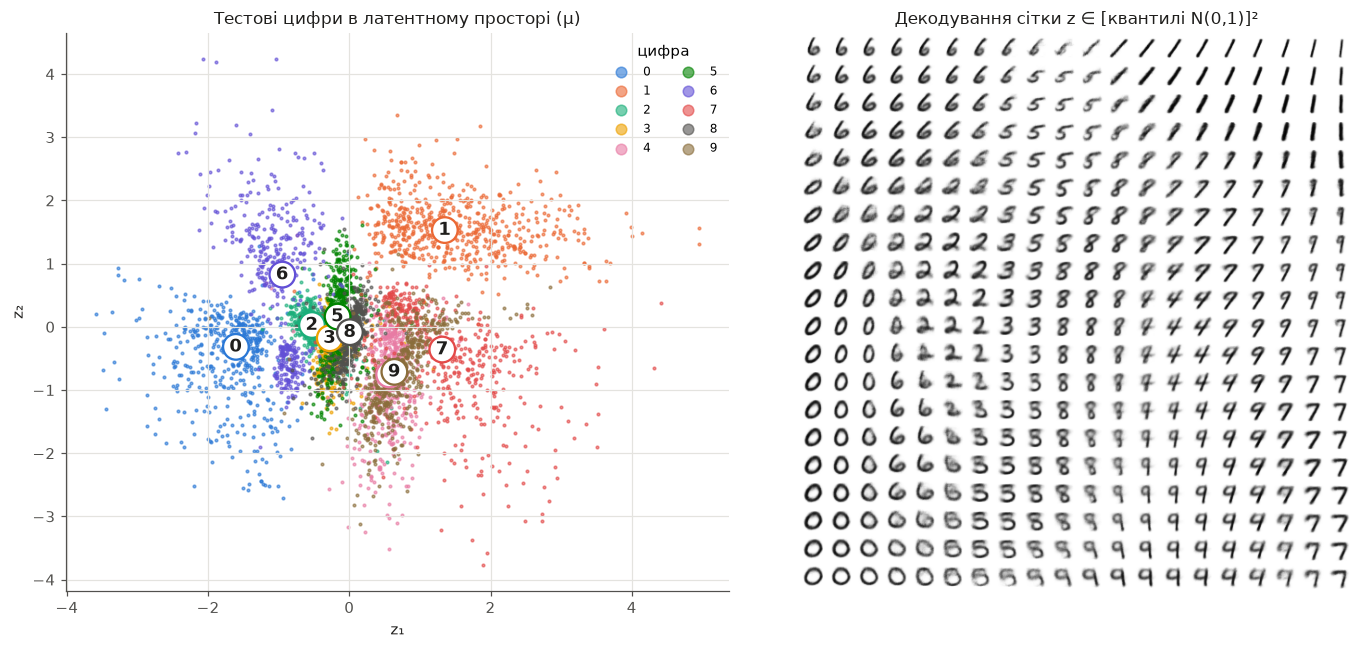

In [11]:
m2, _ = load_run_model(rn({"model.latent_dim": 2}), device)
mu2, y2 = collect_latents(m2, data["test"])
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
latent_scatter(mu2.cpu().numpy(), y2.cpu().numpy(), axes[0], title="Тестові цифри в латентному просторі (μ)")
show_grid(latent_manifold(m2, n=20), 20, axes[1], "Декодування сітки z ∈ [квантилі N(0,1)]²")
fig.tight_layout()
save_fig(fig, "e2_latent_2d")
plt.show()

Діапазон кодів AE: z1 від -21.6 до 21.4, z2 від -2.5 до 39.6


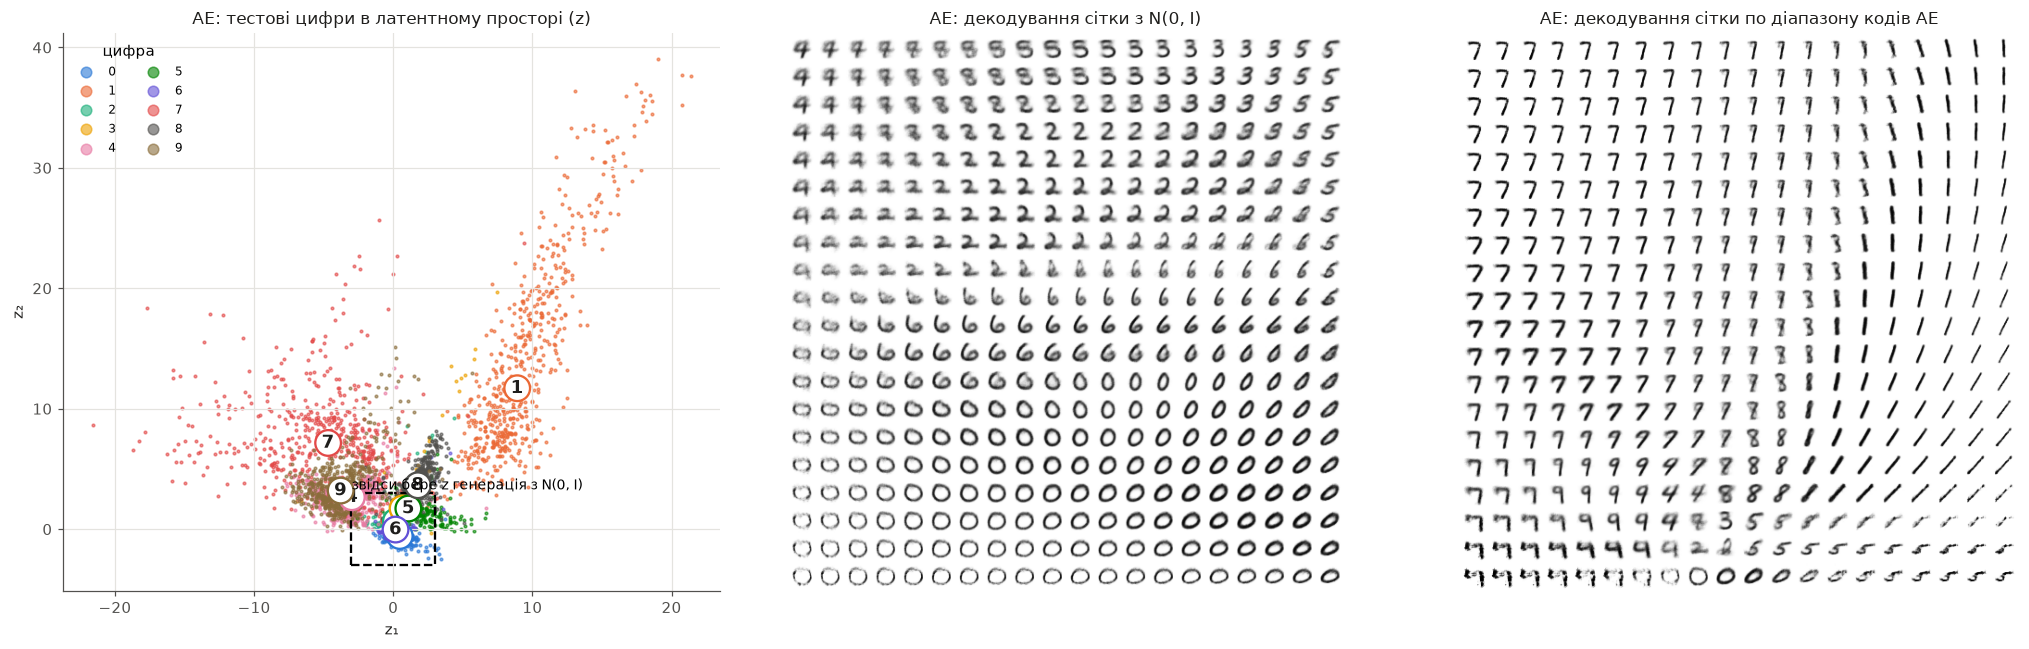

In [27]:
import numpy as np
import torch
from matplotlib.patches import Rectangle
from src.train import train_model

# AE з d = 2, сід 0. run_dir=None → нічого не зберігається в runs/
ae_cfg = load_config(overrides={"model.type": "ae", "model.latent_dim": 2, "seed": 0})
ae2, _, _ = train_model(ae_cfg, run_dir=None, verbose=False)

z_ae, y_ae = collect_latents(ae2, data["test"])   # для AE це самі коди z
z_np = z_ae.cpu().numpy()
print(f"Діапазон кодів AE: z1 від {z_np[:, 0].min():.1f} до {z_np[:, 0].max():.1f}, "
      f"z2 від {z_np[:, 1].min():.1f} до {z_np[:, 1].max():.1f}")

# Сітка по фактичному діапазону кодів AE (1–99 перцентилі, щоб відкинути викиди)
lo, hi = np.percentile(z_np, [1, 99], axis=0)
n = 20
g1, g2 = np.linspace(lo[0], hi[0], n), np.linspace(lo[1], hi[1], n)
zz = torch.tensor([[a, b] for b in g2[::-1] for a in g1], dtype=torch.float32, device=device)
grid_ae_range = ae2.sample(len(zz), z=zz)

fig, axes = plt.subplots(1, 3, figsize=(19, 6))
latent_scatter(z_np, y_ae.cpu().numpy(), axes[0], title="AE: тестові цифри в латентному просторі (z)")
axes[0].add_patch(Rectangle((-3, -3), 6, 6, fill=False, ls="--", lw=1.5, ec="black"))
axes[0].text(-3, 3.3, "звідси бере z генерація з N(0, I)", fontsize=9)
show_grid(latent_manifold(ae2, n=20), 20, axes[1], "AE: декодування сітки з N(0, I)")
show_grid(grid_ae_range, 20, axes[2], "AE: декодування сітки по діапазону кодів AE")
fig.tight_layout()
plt.show()   # без save_fig — у results/figures нічого не з'явиться

## 4. E3 — β-VAE

β < 1: краще відновлення, але латентний простір менше схожий на N(0, I) → генерація з N(0, I) гірша.
β > 1: латенти «стискаються» до N(0, I), відновлення розмиваються, частина вимірів вимикається.

In [12]:
d3 = exp_df("e3_beta")
save_table(agg_table(d3, "beta", ["test_recon", "test_kl", "test_nelbo", "active_units",
                                  "fid_prior", "fid_fitted", "ambiguous_share"]), "e3_beta")

,beta,n,recon (BCE),KL,−ELBO,активні виміри,"FID (N(0,I))",FID (fitted),неоднозначні
0,0.1,3,63.8 ± 0.2,47.2 ± 0.3,111.1 ± 0.1,16.0 ± 0.0,547.7 ± 15.9,406.3 ± 3.0,0.491 ± 0.005
1,0.5,3,68.4 ± 0.2,29.8 ± 0.3,98.1 ± 0.2,16.0 ± 0.0,344.4 ± 19.1,307.2 ± 7.5,0.373 ± 0.014
2,1.0,3,74.9 ± 0.8,21.7 ± 0.6,96.6 ± 0.2,14.0 ± 1.0,277.1 ± 16.0,257.7 ± 16.8,0.315 ± 0.011
3,2.0,3,86.7 ± 2.2,14.8 ± 0.6,101.6 ± 1.6,10.7 ± 1.5,228.4 ± 22.3,225.8 ± 17.7,0.251 ± 0.012
4,4.0,3,103.4 ± 0.6,9.4 ± 0.1,112.9 ± 0.5,8.3 ± 0.6,264.0 ± 9.7,281.3 ± 19.2,0.220 ± 0.007
5,8.0,3,132.9 ± 4.9,4.9 ± 0.4,137.7 ± 4.6,5.7 ± 0.6,606.1 ± 106.1,690.4 ± 113.4,0.292 ± 0.036


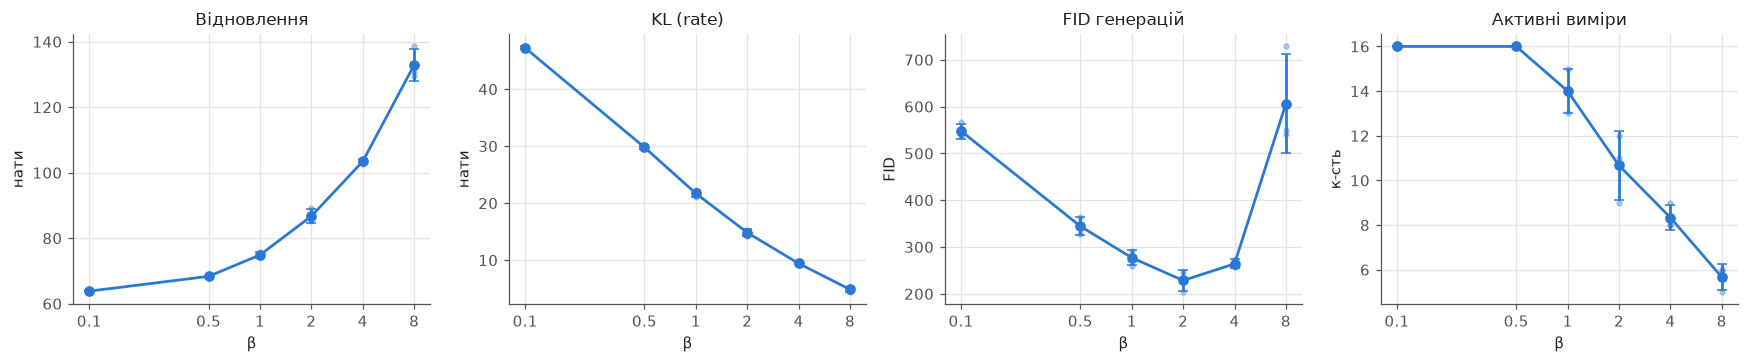

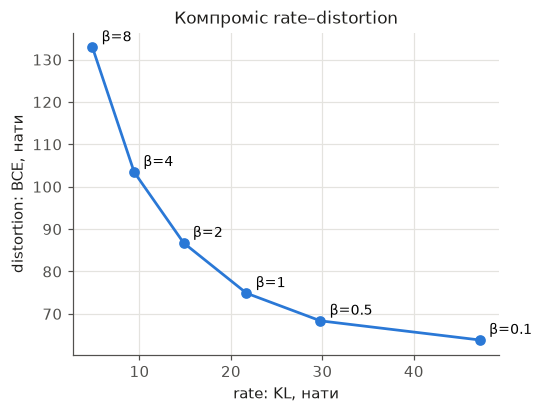

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
plot_metric_vs_param(d3, "beta", "test_recon", axes[0], logx=True, xlabel="β", ylabel="нати", title="Відновлення")
plot_metric_vs_param(d3, "beta", "test_kl", axes[1], logx=True, xlabel="β", ylabel="нати", title="KL (rate)")
plot_metric_vs_param(d3, "beta", "fid_prior", axes[2], logx=True, xlabel="β", ylabel="FID", title="FID генерацій")
plot_metric_vs_param(d3, "beta", "active_units", axes[3], logx=True, xlabel="β", ylabel="к-сть",
                     title="Активні виміри")
fig.tight_layout()
save_fig(fig, "e3_beta_metrics")
plt.show()

# Rate–distortion: кожна точка — β (середнє по сідах)
agg = d3.groupby("beta")[["test_kl", "test_recon"]].mean().reset_index()
fig, ax = plt.subplots(figsize=(5, 3.8))
ax.plot(agg.test_kl, agg.test_recon, marker="o", color=COLORS[0])
for _, r in agg.iterrows():
    ax.annotate(f"β={r.beta:g}", (r.test_kl, r.test_recon), textcoords="offset points", xytext=(6, 4), fontsize=9)
ax.set_xlabel("rate: KL, нати"); ax.set_ylabel("distortion: BCE, нати")
ax.set_title("Компроміс rate–distortion")
save_fig(fig, "e3_rate_distortion")
plt.show()

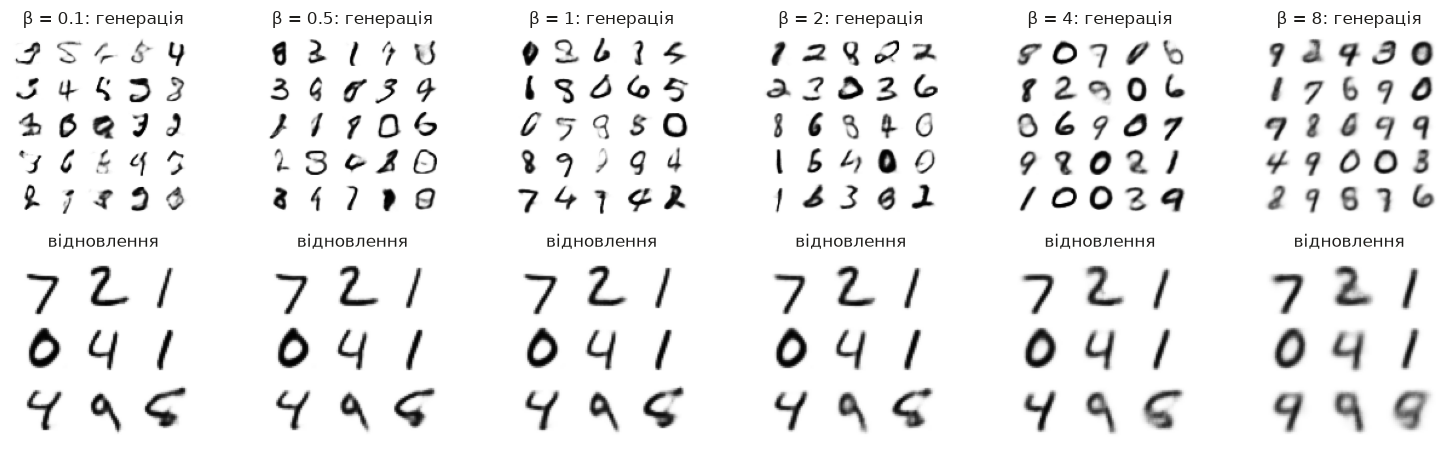

In [14]:
betas = sorted(d3.beta.unique())
fig, axes = plt.subplots(2, len(betas), figsize=(2.3 * len(betas), 4.2))
torch.manual_seed(0)
xs = x_test[:9]
for j, b in enumerate(betas):
    m, _ = load_run_model(rn({"train.beta": float(b)}), device)
    show_grid(m.sample(25), 5, axes[0, j], f"β = {b:g}: генерація")
    show_grid(m.reconstruct(xs), 3, axes[1, j], "відновлення")
fig.tight_layout()
save_fig(fig, "e3_samples")
plt.show()

## 5. E4 — архітектура (MLP проти згорткової)

,arch,n,recon (BCE),−ELBO,"FID (N(0,I))",неоднозначні,"час, с"
0,conv,3,74.9 ± 0.8,96.6 ± 0.2,277.1 ± 16.0,0.315 ± 0.011,78.6 ± 2.1
1,mlp,3,80.6 ± 0.9,100.3 ± 0.6,277.5 ± 13.1,0.309 ± 0.006,59.8 ± 1.5


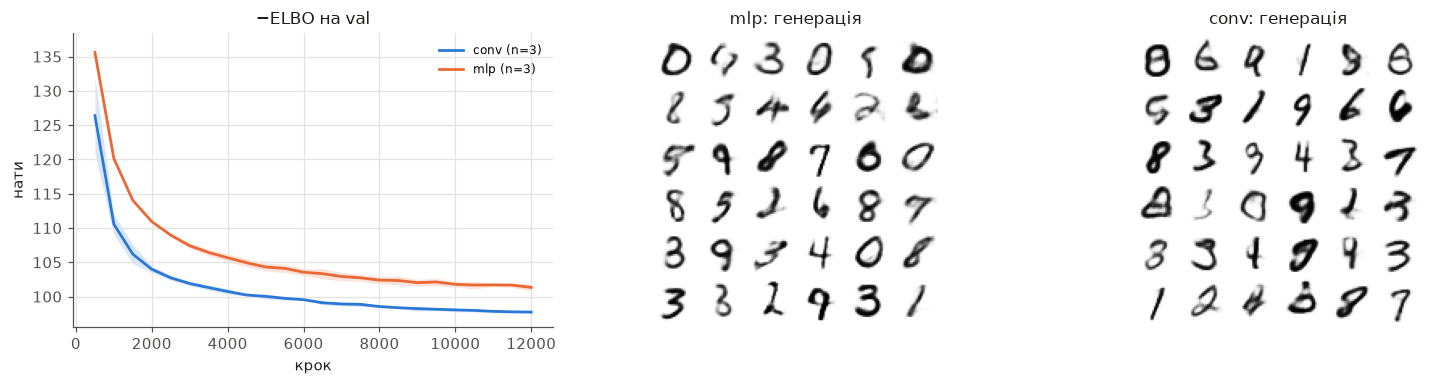

In [15]:
d4 = exp_df("e4_architecture")
display(save_table(agg_table(d4, "arch", ["test_recon", "test_nelbo", "fid_prior", "ambiguous_share",
                                          "train_time_s"]), "e4_architecture"))
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
plot_curves_band({"conv": histories(), "mlp": histories({"model.arch": "mlp"})}, "val_nelbo", axes[0],
                 title="−ELBO на val", ylabel="нати")
torch.manual_seed(0)
for ax, a in zip(axes[1:], ["mlp", "conv"]):
    m, _ = load_run_model(rn({"model.arch": a}), device)
    show_grid(m.sample(36), 6, ax, f"{a}: генерація")
fig.tight_layout()
save_fig(fig, "e4_architecture")
plt.show()

## 6. E5 — вибіркова ефективність

Усі запуски мають однаковий бюджет (12k кроків); з малою часткою даних модель швидше перенавчається,
тому найкращий за val крок настає раніше. Розрив val − train у найкращій точці показує ступінь перенавчання.

In [16]:
d5 = exp_df("e5_data_fraction")


def gap_at_best(run):
    h = load_history(run)
    r = h.iloc[(h.step - df.loc[df.run == run, "best_step"].iloc[0]).abs().argmin()]
    return r.val_loss - r.train_loss


d5["gap"] = d5.run.map(gap_at_best)
d5["n_train"] = d5["n_train"].astype(int)
save_table(agg_table(d5, ["train_fraction", "n_train"], ["test_nelbo", "fid_prior", "ambiguous_share",
                                                         "best_step", "gap"]), "e5_data_fraction")

,train_fraction,n_train,n,−ELBO,"FID (N(0,I))",неоднозначні,найкращий крок,val−train
0,0.02,1100,3,120.5 ± 1.4,527.4 ± 18.2,0.439 ± 0.013,1000.0 ± 0.0,16.9 ± 2.1
1,0.05,2750,3,109.8 ± 0.8,426.4 ± 44.4,0.396 ± 0.028,1666.7 ± 288.7,10.8 ± 1.9
2,0.10,5500,3,105.6 ± 1.0,352.3 ± 9.1,0.361 ± 0.022,3000.0 ± 0.0,9.5 ± 0.7
3,0.25,13750,3,100.0 ± 0.6,297.4 ± 14.1,0.334 ± 0.011,7833.3 ± 1755.9,6.1 ± 1.1
4,0.50,27500,3,98.0 ± 0.8,263.4 ± 8.6,0.319 ± 0.010,11833.3 ± 288.7,3.8 ± 0.4
5,1.00,55000,3,96.6 ± 0.2,277.1 ± 16.0,0.315 ± 0.011,11666.7 ± 288.7,1.8 ± 0.0


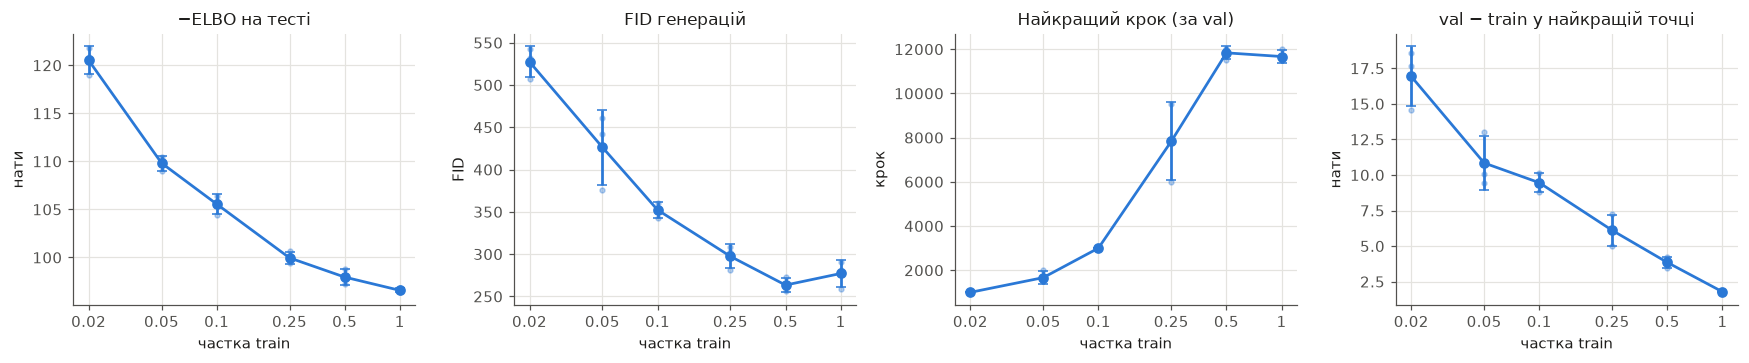

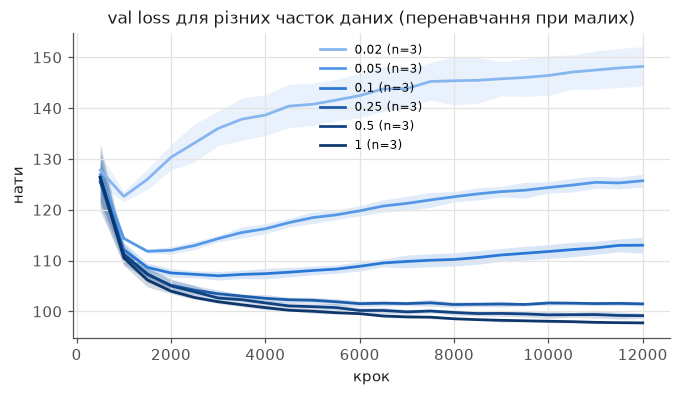

In [17]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
plot_metric_vs_param(d5, "train_fraction", "test_nelbo", axes[0], logx=True, xlabel="частка train",
                     ylabel="нати", title="−ELBO на тесті")
plot_metric_vs_param(d5, "train_fraction", "fid_prior", axes[1], logx=True, xlabel="частка train",
                     ylabel="FID", title="FID генерацій")
plot_metric_vs_param(d5, "train_fraction", "best_step", axes[2], logx=True, xlabel="частка train",
                     ylabel="крок", title="Найкращий крок (за val)")
plot_metric_vs_param(d5, "train_fraction", "gap", axes[3], logx=True, xlabel="частка train",
                     ylabel="нати", title="val − train у найкращій точці")
fig.tight_layout()
save_fig(fig, "e5_sample_efficiency")
plt.show()

fracs = sorted(d5.train_fraction.unique())
hs = {f"{f:g}": histories({"data.train_fraction": float(f)}) for f in fracs}
fig, ax = plt.subplots(figsize=(7, 3.6))
plot_curves_band(hs, "val_loss", ax, colors=ordered_colors(len(fracs)),
                 title="val loss для різних часток даних (перенавчання при малих)", ylabel="нати")
save_fig(fig, "e5_curves")
plt.show()

## 7. E6 — Conditional VAE

`cond_acc` — частка генерацій, у яких класифікатор-оцінювач впізнав саме ту цифру, яку ми просили.

In [18]:
d6 = exp_df("e6_cvae")
save_table(agg_table(d6, "latent_dim", ["cond_acc", "test_recon", "test_kl", "fid_prior",
                                        "ambiguous_share"]), "e6_cvae")

,latent_dim,n,cond. acc,recon (BCE),KL,"FID (N(0,I))",неоднозначні
0,2,3,0.997 ± 0.001,124.7 ± 0.1,4.9 ± 0.1,214.1 ± 4.5,0.012 ± 0.002
1,8,3,0.968 ± 0.010,82.7 ± 0.9,14.5 ± 0.0,65.2 ± 13.2,0.062 ± 0.014
2,16,3,0.968 ± 0.004,76.8 ± 2.1,17.4 ± 1.0,56.8 ± 4.9,0.063 ± 0.008


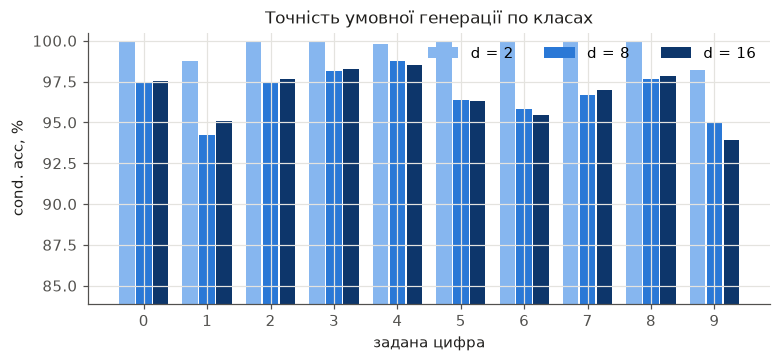

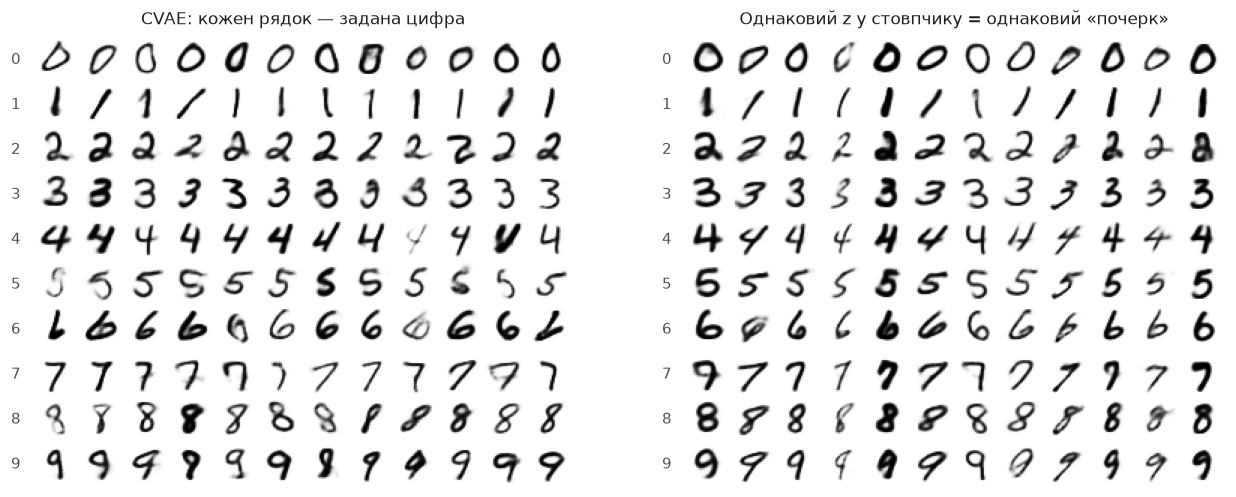

In [19]:
cvae_dims = sorted(d6.latent_dim.unique())
per_class = {dd: np.mean([r for r in d6[d6.latent_dim == dd].cond_acc_per_class], axis=0) for dd in cvae_dims}
fig, ax = plt.subplots(figsize=(8, 3.2))
w = 0.8 / len(cvae_dims)
for i, (dd, acc) in enumerate(per_class.items()):
    ax.bar(np.arange(10) + (i - (len(cvae_dims) - 1) / 2) * w, acc * 100, width=w * 0.92,
           color=ordered_colors(len(cvae_dims))[i], label=f"d = {dd}")
ax.set_xticks(range(10)); ax.set_xlabel("задана цифра"); ax.set_ylabel("cond. acc, %")
ax.set_ylim(max(0, min(a.min() for a in per_class.values()) * 100 - 10), 100.5)
ax.set_title("Точність умовної генерації по класах"); ax.legend(ncol=3)
save_fig(fig, "e6_cond_acc_per_class")
plt.show()

cv, _ = load_run_model(rn({"model.type": "cvae"}), device)
torch.manual_seed(0)
labels = torch.arange(10, device=device).repeat_interleave(12)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.4))
show_grid(cv.sample(120, y=labels), 10, axes[0], "CVAE: кожен рядок — задана цифра", ylabels=list(range(10)))
# «стиль»: той самий z (стовпчик) з різними мітками (рядки)
z = torch.randn(12, cv.latent_dim, device=device)
style = torch.cat([cv.sample(12, y=torch.full((12,), c, device=device), z=z) for c in range(10)])
show_grid(style, 10, axes[1], "Однаковий z у стовпчику = однаковий «почерк»", ylabels=list(range(10)))
save_fig(fig, "e6_cvae_samples")
plt.show()

## 8. Стабільність між сідами

Коефіцієнт варіації (CV = std / mean) по 3 сідах для кожної конфігурації. Високий CV → результат
сильно залежить від ініціалізації / підвибірки; такі висновки треба формулювати обережно.

In [20]:
KEY = ["model_type", "arch", "latent_dim", "beta", "train_fraction"]
uniq = df.drop_duplicates("run")
stab = uniq.groupby(KEY).agg(n=("seed", "size"),
                             nelbo_mean=("test_nelbo", "mean"), nelbo_std=("test_nelbo", "std"),
                             fid_mean=("fid_prior", "mean"), fid_std=("fid_prior", "std")).reset_index()
stab["nelbo_cv_%"] = 100 * stab.nelbo_std / stab.nelbo_mean
stab["fid_cv_%"] = 100 * stab.fid_std / stab.fid_mean
stab = stab.sort_values("fid_cv_%", ascending=False).round(3)
save_table(stab, "stability")
n_div = (df_all.drop_duplicates("run").status != "ok").sum()
print(f"Розбіжних запусків: {n_div}")
stab

Розбіжних запусків: 0


,model_type,arch,latent_dim,beta,train_fraction,n,nelbo_mean,nelbo_std,fid_mean,fid_std,nelbo_cv_%,fid_cv_%
2,cvae,conv,8,1.0,1.00,3,97.202,0.872,65.245,13.222,0.897,20.266
17,vae,conv,16,8.0,1.00,3,137.735,4.558,606.062,106.126,3.309,17.511
6,vae,conv,8,1.0,1.00,3,102.413,0.354,238.160,37.035,0.346,15.550
0,ae,conv,16,1.0,1.00,3,63.082,0.106,1943.414,229.817,0.168,11.825
19,vae,conv,64,1.0,1.00,3,97.185,0.543,287.370,31.451,0.558,10.945
10,vae,conv,16,1.0,0.05,3,109.826,0.779,426.362,44.434,0.709,10.422
15,vae,conv,16,2.0,1.00,3,101.563,1.605,228.444,22.341,1.580,9.779
4,vae,conv,2,1.0,1.00,3,143.647,1.016,641.856,61.677,0.707,9.609
3,cvae,conv,16,1.0,1.00,3,94.220,1.136,56.823,4.926,1.205,8.669
14,vae,conv,16,1.0,1.00,3,96.577,0.208,277.129,16.042,0.215,5.789


## 9. Аналіз помилок

### 9.1 Наскільки «неоднозначні» генерації порівняно зі справжніми цифрами
Частка зображень, де класифікатор упевнений менш ніж на 90%. Якщо в генераціях вона значно більша,
ніж у справжніх цифр, — модель додає «незрозумілі» цифри понад природну неоднозначність почерку.

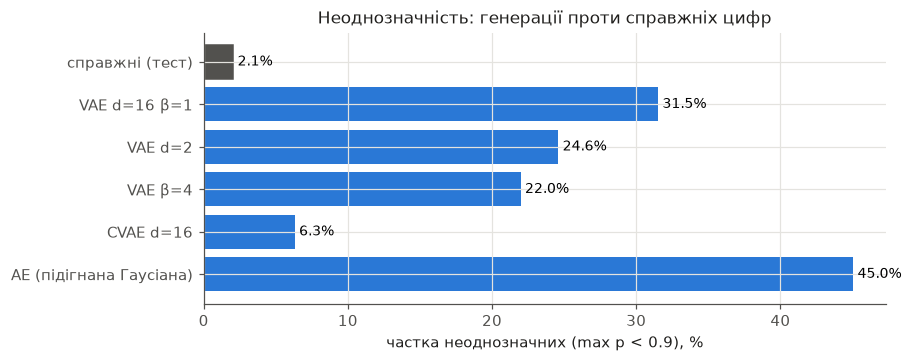

In [21]:
def mean_metric(ov, col="ambiguous_share"):
    return df[df.run.isin(runs_for(ov))][col].mean()


amb = {
    "справжні (тест)": REF.get("real_ambiguous_share_test", df.real_ambiguous_share.mean()),
    "VAE d=16 β=1": mean_metric(None),
    "VAE d=2": mean_metric({"model.latent_dim": 2}),
    "VAE β=4": mean_metric({"train.beta": 4.0}),
    "CVAE d=16": mean_metric({"model.type": "cvae"}),
    "AE (підігнана Гаусіана)": mean_metric({"model.type": "ae"}, "ambiguous_share_fitted"),
}
amb = {k: v for k, v in amb.items() if pd.notna(v)}
fig, ax = plt.subplots(figsize=(8, 3.2))
bars = ax.barh(list(amb.keys())[::-1], [v * 100 for v in list(amb.values())[::-1]], color=COLORS[0])
bars[-1].set_color(MUTED)
for b, v in zip(bars, list(amb.values())[::-1]):
    ax.text(b.get_width() + 0.3, b.get_y() + b.get_height() / 2, f"{v * 100:.1f}%", va="center", fontsize=9)
ax.set_xlabel("частка неоднозначних (max p < 0.9), %")
ax.set_title("Неоднозначність: генерації проти справжніх цифр")
save_fig(fig, "err_ambiguity")
plt.show()

### 9.2 Найменш «впізнавані» генерації та розподіл класів

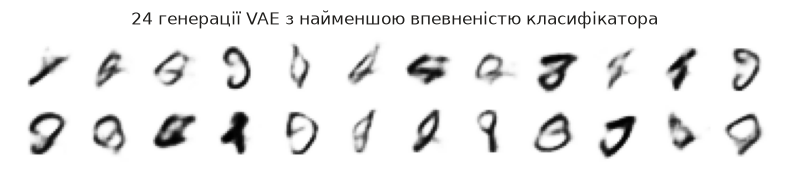

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
топ-1,1,8,5,0,6,4,5,2,8,5,1,2,0,0,4,9,5,4,2,3,3,2,5,0
топ-2,8,9,8,9,1,0,8,0,7,9,7,0,9,8,6,8,7,1,4,8,0,7,2,9
впевненість,0.25,0.25,0.26,0.27,0.27,0.27,0.27,0.28,0.3,0.3,0.3,0.31,0.31,0.31,0.31,0.32,0.32,0.33,0.33,0.33,0.33,0.33,0.33,0.33


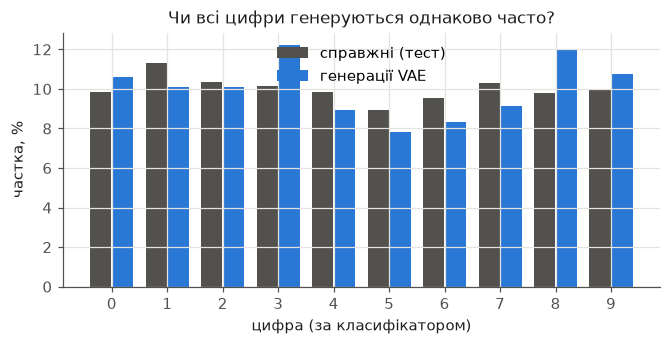

In [22]:
torch.manual_seed(1)
gen = vae.sample(5000)
_, p_gen = classifier_outputs(clf, gen)
conf = p_gen.max(1)
worst = np.argsort(conf)[:24]
fig, ax = plt.subplots(figsize=(9, 1.7))
show_grid(gen[worst], 2, ax, "24 генерації VAE з найменшою впевненістю класифікатора")
save_fig(fig, "err_ambiguous_samples")
plt.show()
top2 = np.argsort(-p_gen[worst], axis=1)[:, :2]
display(pd.DataFrame({"топ-1": top2[:, 0], "топ-2": top2[:, 1], "впевненість": conf[worst].round(2)}).astype(str).T)

_, p_real = classifier_outputs(clf, x_test)
h_gen = np.bincount(p_gen.argmax(1), minlength=10) / len(p_gen) * 100
h_real = np.bincount(p_real.argmax(1), minlength=10) / len(p_real) * 100
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(np.arange(10) - 0.2, h_real, 0.38, color=MUTED, label="справжні (тест)")
ax.bar(np.arange(10) + 0.2, h_gen, 0.38, color=COLORS[0], label="генерації VAE")
ax.set_xticks(range(10)); ax.set_xlabel("цифра (за класифікатором)"); ax.set_ylabel("частка, %")
ax.set_title("Чи всі цифри генеруються однаково часто?"); ax.legend()
save_fig(fig, "err_class_balance")
plt.show()

### 9.3 Найгірше відновлені тестові цифри

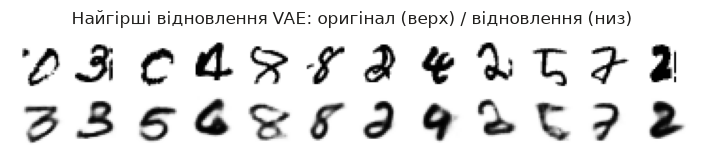

Цифри: [0, 3, 0, 4, 8, 8, 2, 4, 2, 5, 2, 2] | BCE: [233.0, 209.0, 208.0, 184.0, 181.0, 181.0, 180.0, 178.0, 173.0, 170.0, 169.0, 166.0]


In [23]:
with torch.no_grad():
    bce = torch.cat([reconstruction_loss(vae(xb, yb, sample=False)["logits"], xb) for xb, yb in data["test"]])
worst = torch.argsort(bce, descending=True)[:12]
fig, ax = plt.subplots(figsize=(8, 1.6))
show_grid(torch.cat([x_test[worst], vae.reconstruct(x_test[worst])]), 2, ax,
          "Найгірші відновлення VAE: оригінал (верх) / відновлення (низ)")
save_fig(fig, "err_worst_recon")
plt.show()
print("Цифри:", y_test[worst].tolist(), "| BCE:", bce[worst].round().tolist())

### 9.4 Помилки CVAE: яку цифру просили → яку отримали

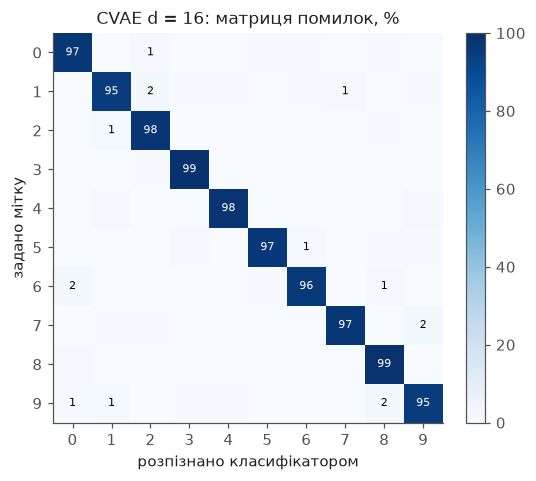

In [26]:
cv2, _ = load_run_model(rn({"model.type": "cvae", "model.latent_dim": int(cvae_dims[-1])}), device)
torch.manual_seed(0)
req = torch.arange(10, device=device).repeat_interleave(500)
_, p_cv = classifier_outputs(clf, cv2.sample(len(req), y=req))
cm = np.zeros((10, 10))
np.add.at(cm, (req.cpu().numpy(), p_cv.argmax(1)), 1)
cm = cm / cm.sum(1, keepdims=True) * 100
fig, ax = plt.subplots(figsize=(5.4, 4.6))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=100)
for i in range(10):
    for j in range(10):
        if cm[i, j] >= 1:
            ax.text(j, i, f"{cm[i, j]:.0f}", ha="center", va="center", fontsize=7,
                    color="white" if cm[i, j] > 60 else "black")
ax.set_xticks(range(10)); ax.set_yticks(range(10)); ax.grid(False)
ax.set_xlabel("розпізнано класифікатором"); ax.set_ylabel("задано мітку")
ax.set_title(f"CVAE d = {cvae_dims[-1]}: матриця помилок, %")
fig.colorbar(im, ax=ax, fraction=0.046)
save_fig(fig, "err_cvae_confusion")
plt.show()

## 10. Інтерполяції в латентному просторі

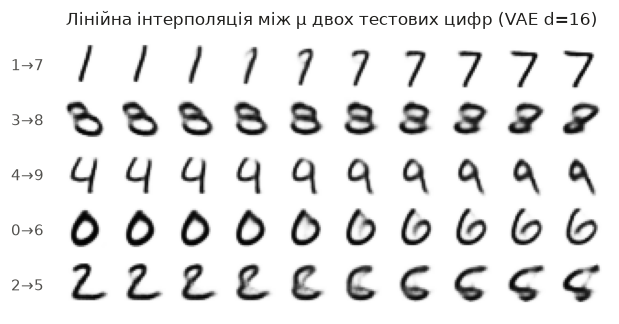

In [25]:
pairs = [(1, 7), (3, 8), (4, 9), (0, 6), (2, 5)]
rows = []
for a, b in pairs:
    ia = int((y_test == a).nonzero()[0]); ib = int((y_test == b).nonzero()[0])
    rows.append(interpolate(vae, x_test[ia], x_test[ib], steps=10))
fig, ax = plt.subplots(figsize=(6.5, 3.6))
show_grid(torch.cat(rows), len(pairs), ax, "Лінійна інтерполяція між μ двох тестових цифр (VAE d=16)",
          ylabels=[f"{a}→{b}" for a, b in pairs])
save_fig(fig, "interpolations")
plt.show()

## 11. Висновки

1. **AE проти VAE (E1).** AE відновлює краще (BCE 63.1 проти 74.9 нат), але генерація з N(0, I) у нього непридатна:
   FID 1943 проти 277 у VAE, 90% неоднозначних зразків проти 31.5%. З гаусіаною, підігнаною до кодів, FID AE падає до 440,
   але залишається гіршим за VAE через «дірки» між кластерами кодів (`e1_samples.png`).
   Висновок: для генерації потрібен KL-доданок.

2. **Збіжність.** Train і val ідуть разом, розрив у кінці ≈ 1.8 нат, тож перенавчання немає. KL виходить на плато
   (~22 нат) вже за ~3000 кроків, відновлення повільно покращується до кінця. Найкращий крок ≈ 11.5–12k,
   тобто повної збіжності за 12k кроків немає, хоча крива майже пласка (`convergence_main.png`).

3. **Розмір латенту (E2).** −ELBO виходить на плато при d = 16 (96.6; 97.0 і 97.2 при d = 32 і 64).
   Активних вимірів 14 / 16 / 18 при d = 16 / 32 / 64, тобто модель використовує ~14–18 вимірів, а решту вимикає
   (posterior collapse, `e2_kl_per_dim.png`). Найкращий FID при d = 8 (238 ± 37) — лише тенденція через великий розкид.
   При d = 2 VAE без міток розділяє класи, але 2, 3, 5, 8 і 4/9 перекриваються (`e2_latent_2d.png`).

4. **β-VAE (E3).** Класичний компроміс rate–distortion: з ростом β KL падає (47 → 5 нат), відновлення погіршується
   (64 → 133 нат), активних вимірів стає менше (16 → 6) (`e3_rate_distortion.png`). Мінімум −ELBO при β = 1,
   найкращий FID при β = 2 (228): правдоподібність і якість зразків — різні цілі. При β = 8 відновлення змінюють
   клас цифри (`e3_samples.png`).

5. **Архітектура (E4).** Conv краща за −ELBO (96.6 проти 100.3), але FID однаковий (277 проти 278), і навчання
   на 31% довше. Вузьке місце генерації — латентний простір, а не декодер.

6. **Вибіркова ефективність (E5).** 25% даних дають −ELBO лише на 3.4 нат (3.5%) гірший за повний набір.
   При ≤ 10% модель перенавчається: найкращий крок зсувається до 1000–3000, розрив val − train зростає до 16.9 нат.
   Вибір чекпоінту за val на 2% даних покращує результат на ~25 нат (`e5_curves.png`).

7. **CVAE (E6).** Задана цифра генерується в 96.8% випадків (d = 16), FID 57 проти 277 у VAE, неоднозначних 6.3%.
   z кодує стиль, мітка — клас (`e6_cvae_samples.png`). При d = 2 точність 99.7%, але FID гірший (214):
   генерації типові, проте не різноманітні. Найважче даються 1, 9 і 6.

8. **Стабільність.** 0 розбіжних запусків. CV −ELBO між сідами < 1.2% (до 3.3% при β = 8), CV FID до 20%,
   тому різниці FID < ~15% не вважаємо значущими.

9. **Помилки та обмеження.** Неоднозначних генерацій VAE 31.5% проти 2.05% у справжніх цифр. Причина — потрапляння z
   між областями класів, а не якість декодера: у CVAE з таким самим відновленням їх у 5 разів менше
   (`err_ambiguity.png`). Найгірше відновлюються нетипові цифри: VAE «підтягує» їх до типових (`err_worst_recon.png`).
   Обмеження: Bernoulli-правдоподібність для сірих пікселів, FID на власному класифікаторі (не порівнюваний зі статтями),
   −ELBO лише верхня межа, неповна збіжність, lr не підбирався, 3 сіди, лише MNIST.